# Clinical NLP Specialty Classification

This notebook is the end-to-end walkthrough for the repository. It uses the same functions as the command-line training pipeline and compares:

1. Full text → TF-IDF → logistic regression
2. Biomedical entities only → TF-IDF → logistic regression
3. Full text + entities → TF-IDF → logistic regression
4. Full text → BioClinicalBERT fine-tuning

Downloaded data, NER caches, checkpoints, and model weights remain local and are excluded from Git.

> **Kernel:** Select `Python (clinical-nlp)`. If it is unavailable, run:
>
> ```bash
> python -m ipykernel install --user --name clinical-nlp-specialty-classification --display-name "Python (clinical-nlp)"
> ```

In [13]:
from pathlib import Path
import importlib
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# Ensure reruns use the current files rather than stale modules cached by Jupyter.
importlib.invalidate_caches()
for module_name in [
    name for name in sys.modules
    if name == "src" or name.startswith("src.")
]:
    sys.modules.pop(module_name, None)

from src.baseline import train_baseline_experiments
from src.data import load_clinical_notes, save_splits, split_frame
from src.evaluate import (
    plot_class_distribution,
    plot_note_lengths,
    plot_note_length_by_specialty,
)
from src.ner import enrich_with_entities, load_ner_pipeline
from src.train_bert import evaluate_trainer, save_final_model, train_bioclinicalbert
from src.utils import configure_plots, set_seed

set_seed(42)
configure_plots()

RAW_DATA = PROJECT_ROOT / "data" / "mtsamples.csv"
NER_CACHE = PROJECT_ROOT / "data" / "mtsamples_with_ner.csv"
RUN_NER = False   # Slow: set True to create/rebuild the entity cache
RUN_BERT = False  # Compute-intensive: set True to fine-tune BioClinicalBERT
SAVE_FINAL_BERT = False

## 1. Load and clean MTSamples

`load_clinical_notes` removes missing transcriptions/labels, strips specialty whitespace, keeps the six target specialties, and calculates word counts. The canonical split is stratified with `random_state=42`.

In [14]:
DATA_AVAILABLE = RAW_DATA.exists()

if DATA_AVAILABLE:
    notes = load_clinical_notes(RAW_DATA)
    train_df, test_df = split_frame(notes)
    save_splits(notes, PROJECT_ROOT / "data")

    print(f"All notes: {len(notes):,}")
    print(f"Train: {len(train_df):,} | Test: {len(test_df):,}")
    display(notes.head(3))
else:
    notes = train_df = test_df = None
    print("Dataset not found. Place mtsamples.csv in data/ to run training cells.")
    print("The preserved results and figures below remain available.")

Dataset not found. Place mtsamples.csv in data/ to run training cells.
The preserved results and figures below remain available.


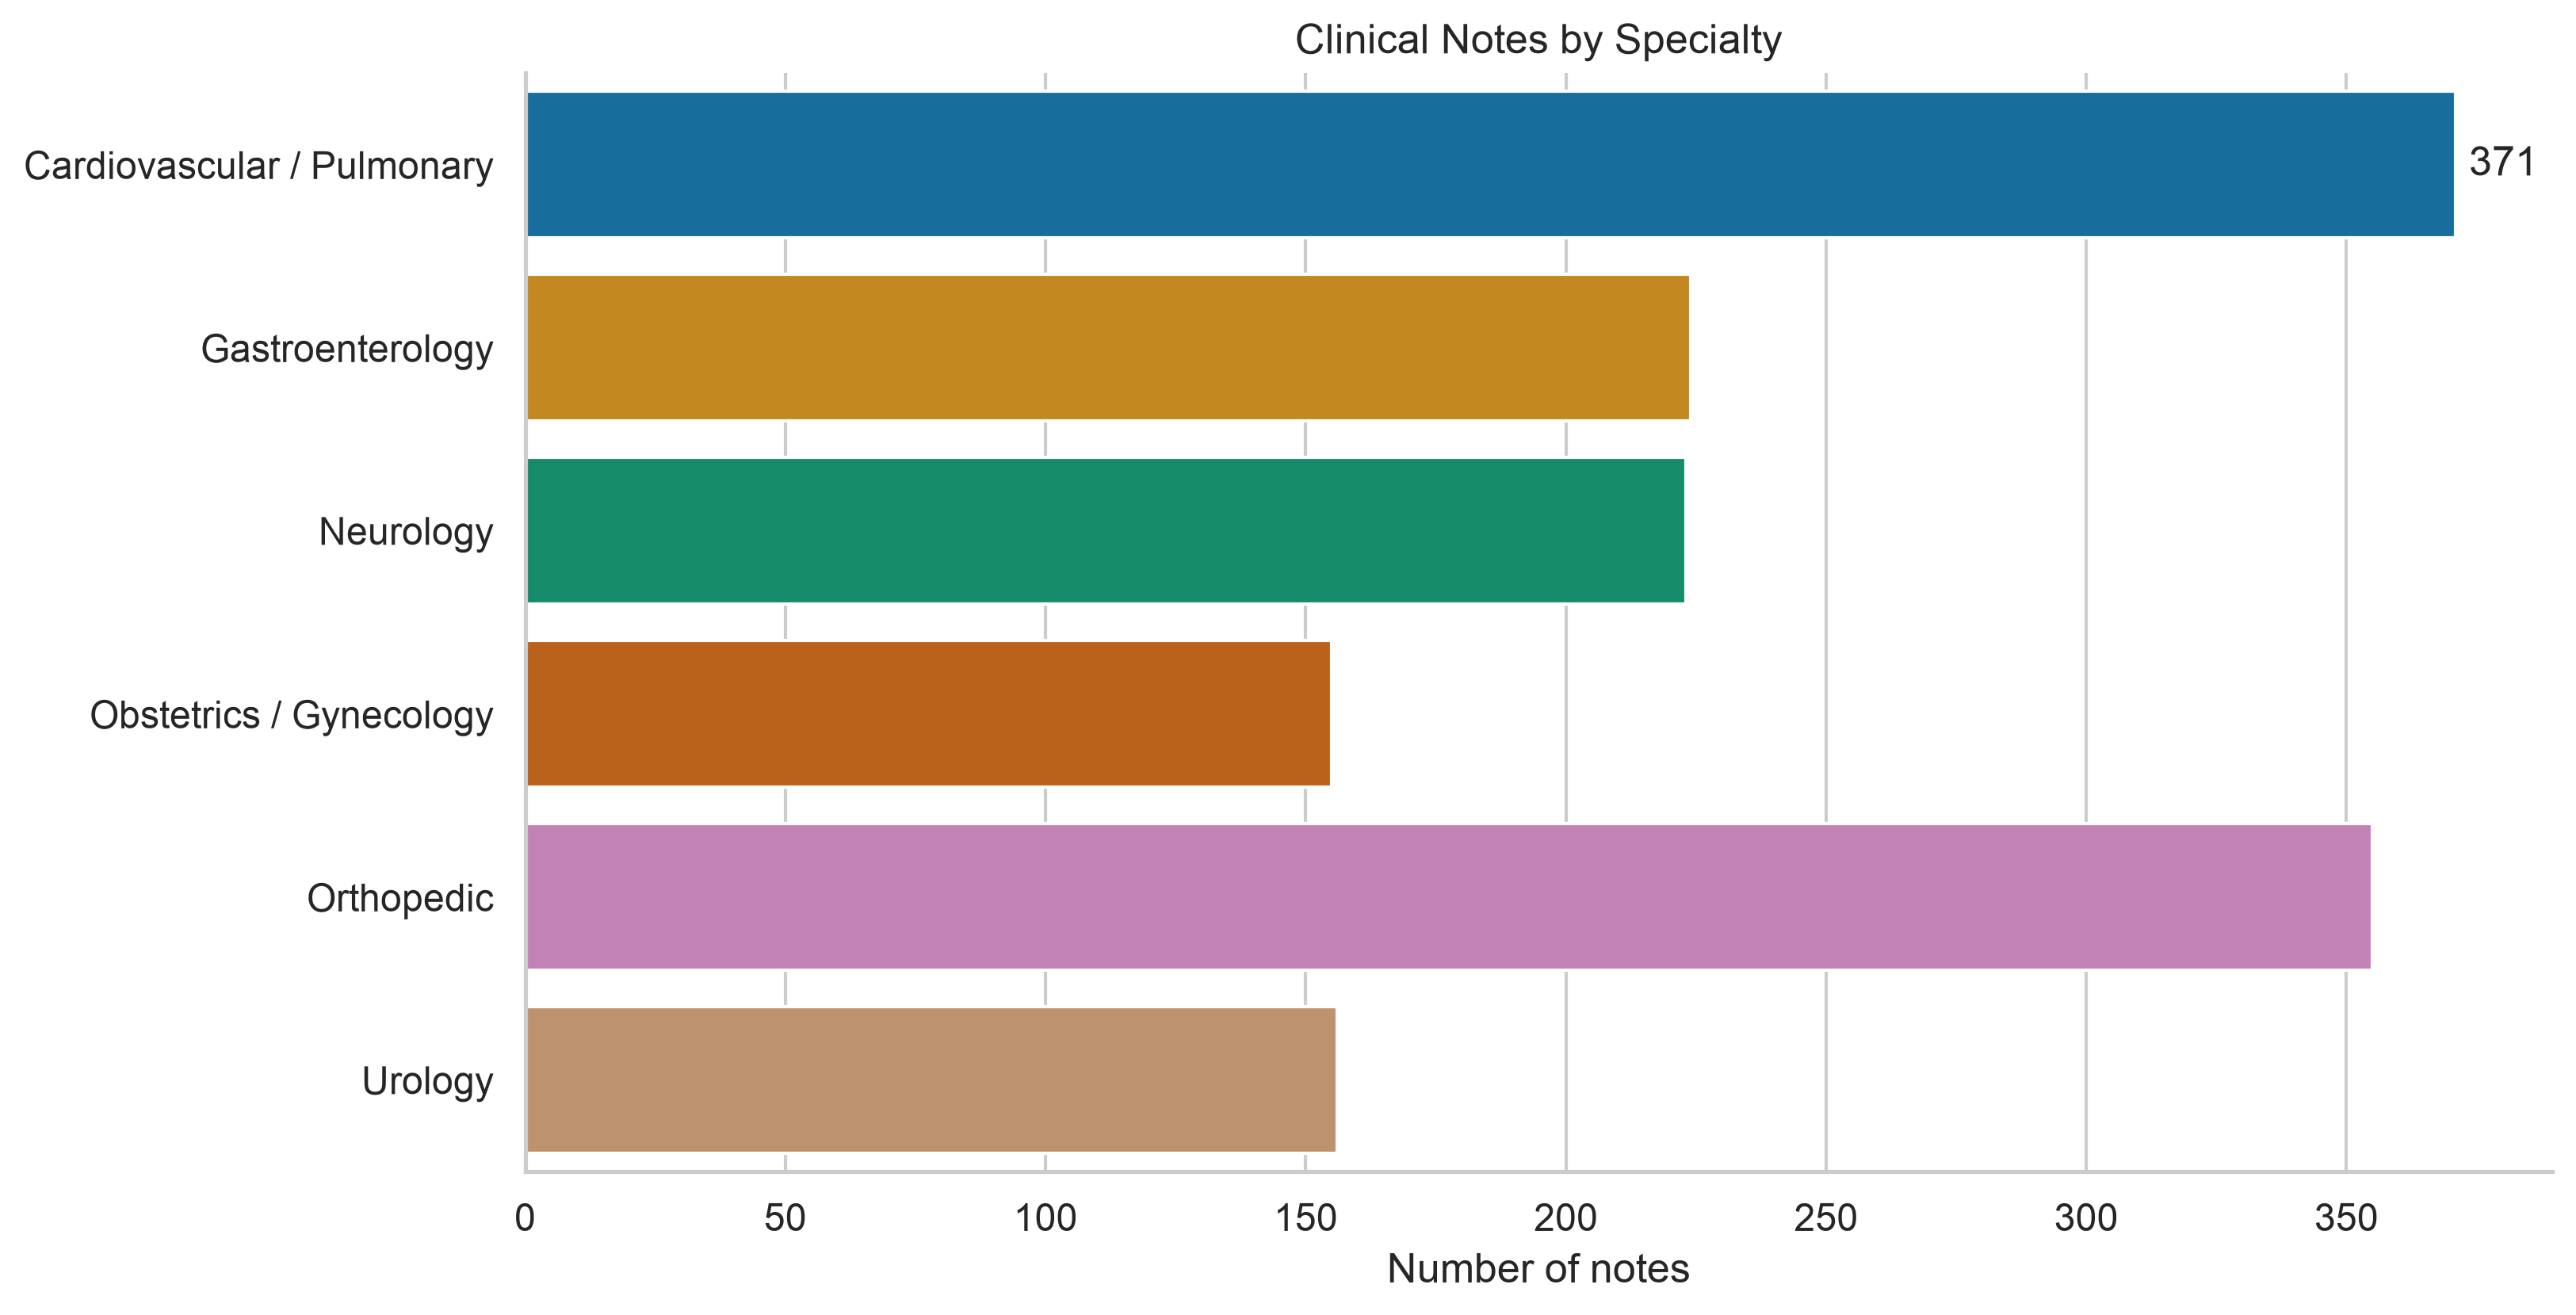

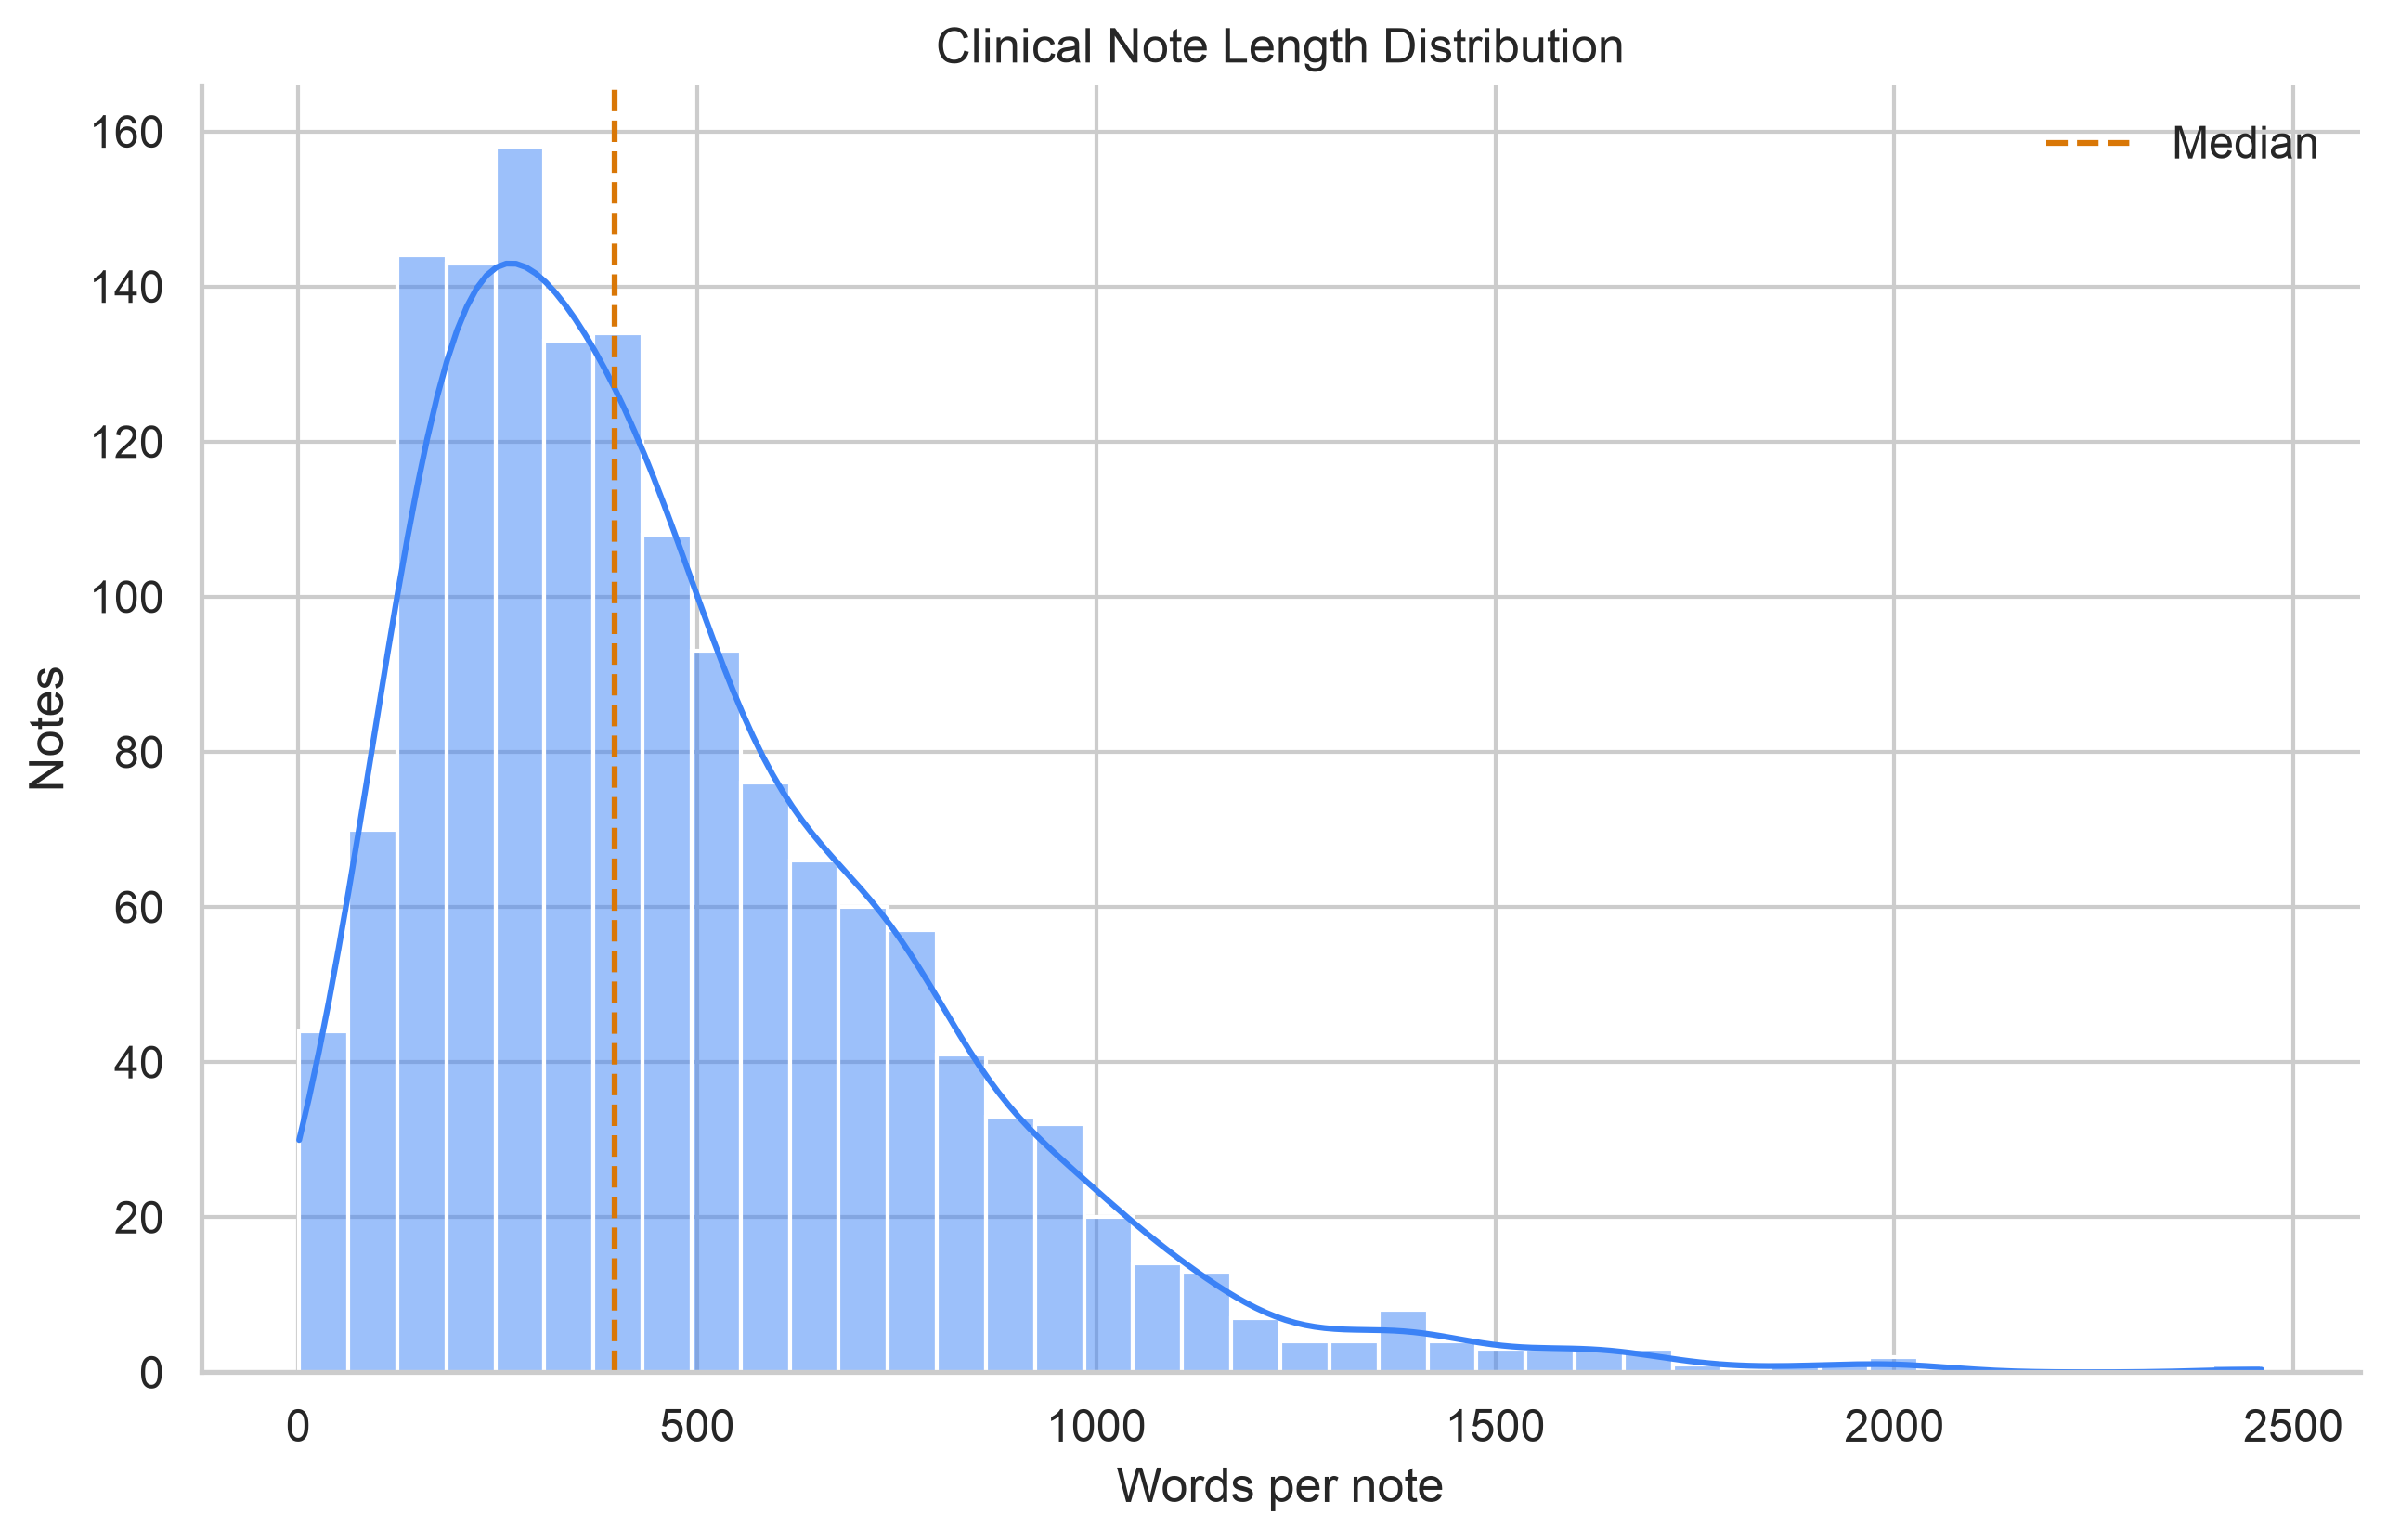

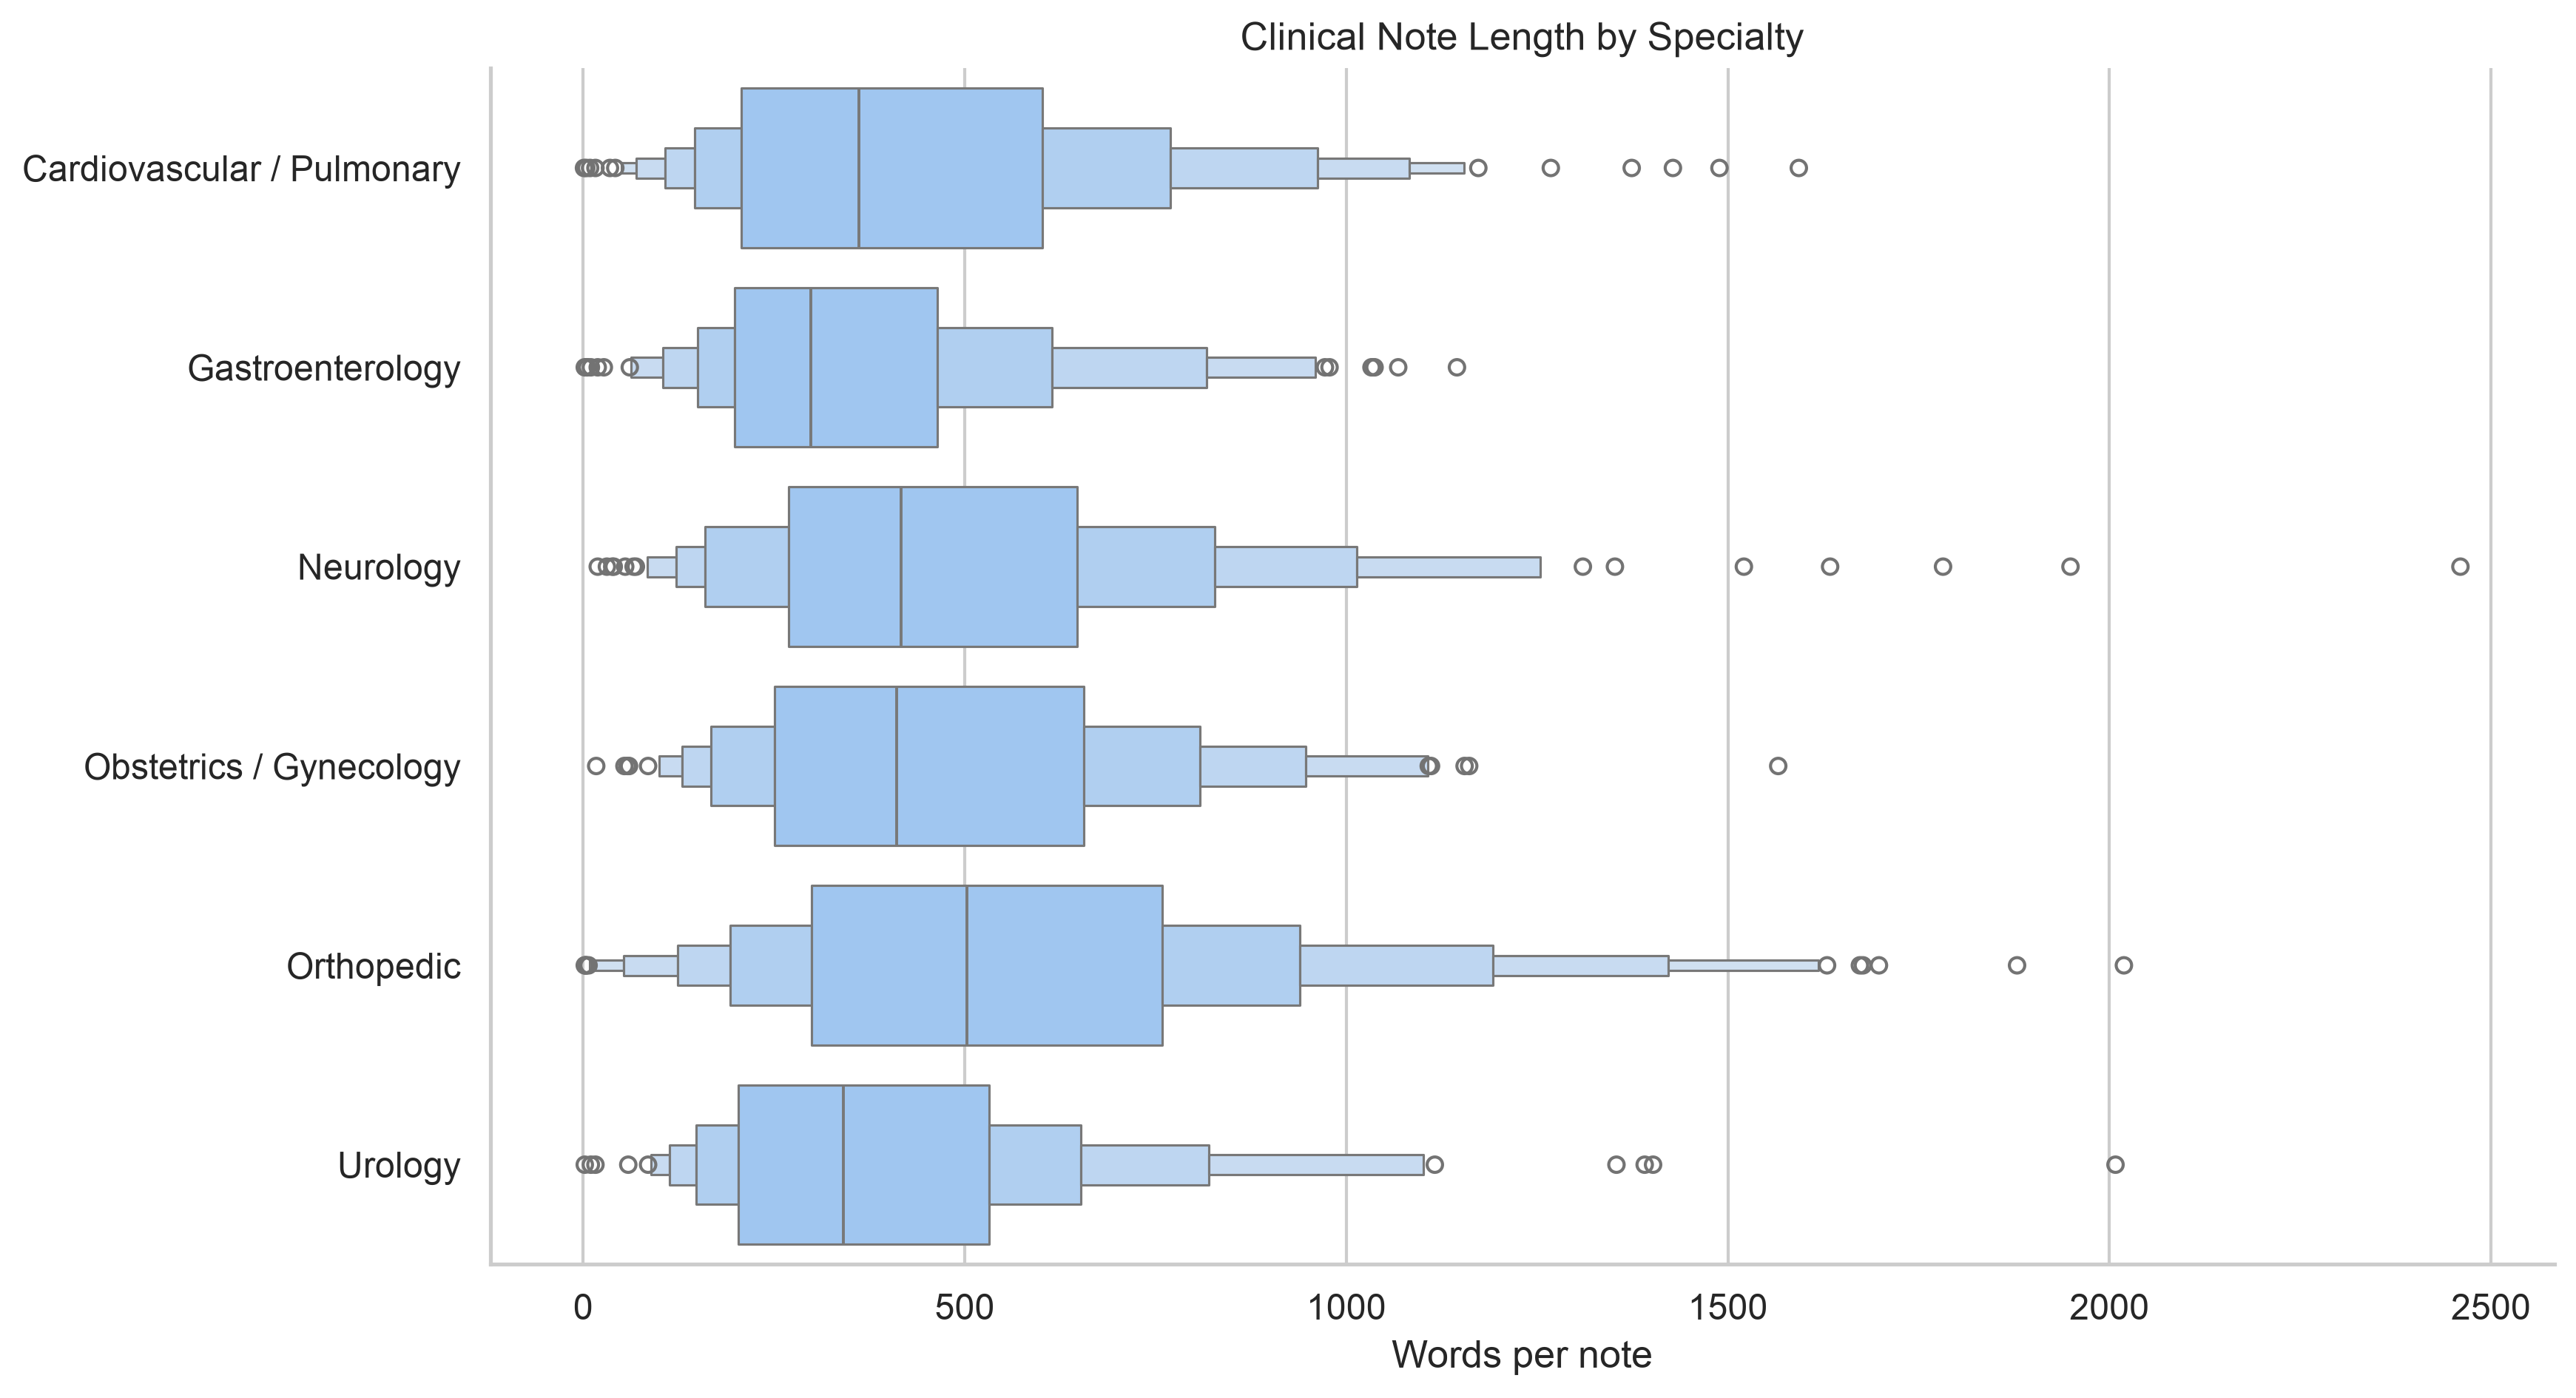

In [15]:
if DATA_AVAILABLE:
    plot_class_distribution(notes)
    plot_note_lengths(notes)
    plot_note_length_by_specialty(notes)
else:
    display(Image(filename=PROJECT_ROOT / "figures" / "class_distribution.png", width=850))
    display(Image(filename=PROJECT_ROOT / "figures" / "note_length_distribution.png", width=850))
    display(Image(filename=PROJECT_ROOT / "figures" / "note_length_by_specialty.png", width=850))

## 2. Extract biomedical entities

The NER stage uses `d4data/biomedical-ner-all`, processes the first 2,000 characters to match the original experiment, and saves entity text, entity groups, counts, and failures. The cache checkpoints every 25 rows and resumes interrupted runs.

In [16]:
if RUN_NER and DATA_AVAILABLE:
    ner_pipeline = load_ner_pipeline(device="auto")
    notes_with_ner = enrich_with_entities(
        notes,
        NER_CACHE,
        ner_pipeline,
        checkpoint_every=25,
    )
elif NER_CACHE.exists():
    notes_with_ner = load_clinical_notes(NER_CACHE)
else:
    notes_with_ner = None
    print("Add mtsamples.csv and set RUN_NER=True to create the NER cache.")

## 3. Train the three TF-IDF experiments

One function trains all three representations on the same split and saves metrics, reports, predictions, errors, top features, and optional model pipelines.

In [17]:
if notes_with_ner is not None:
    baseline_metrics, baseline_reports = train_baseline_experiments(
        notes_with_ner,
        output_dir=PROJECT_ROOT / "results" / "baselines",
        model_dir=PROJECT_ROOT / "models" / "baselines",
    )
    display(baseline_metrics.style.format({"Accuracy": "{:.6f}", "Macro_F1": "{:.6f}"}))
else:
    print("NER cache unavailable; showing preserved results in Section 5.")

,Model,Input,Accuracy,Macro_F1
0,TF-IDF + Logistic Regression,Full clinical text,0.898990,0.897036
1,NER-only + TF-IDF + Logistic Regression,Biomedical entities only,0.841751,0.833777
2,Full Text + NER + TF-IDF + Logistic Regression,Full text + biomedical entities,0.895623,0.894816


## 4. Fine-tune BioClinicalBERT

The transformer pipeline creates Hugging Face Datasets, applies `max_length=256`, fine-tunes `emilyalsentzer/Bio_ClinicalBERT` for two epochs, and evaluates accuracy plus macro-F1. `Trainer` supports CUDA, Apple Silicon MPS, and CPU.

In [18]:
if RUN_BERT and DATA_AVAILABLE:
    trainer, tokenized_test, tokenizer = train_bioclinicalbert(
        train_df,
        test_df,
        output_dir=PROJECT_ROOT / "models" / "bioclinicalbert",
        epochs=2,
        batch_size=8,
        learning_rate=2e-5,
        weight_decay=0.01,
        max_length=256,
        device="auto",
    )
    bert_metrics, bert_report = evaluate_trainer(
        trainer,
        tokenized_test,
        test_df,
        output_dir=PROJECT_ROOT / "results" / "bert",
    )
    if SAVE_FINAL_BERT:
        save_final_model(
            trainer,
            tokenizer,
            PROJECT_ROOT / "models" / "final_bioclinicalbert",
        )
    display(bert_metrics)
elif RUN_BERT:
    print("BioClinicalBERT training requires data/mtsamples.csv.")
else:
    print("RUN_BERT=False; showing preserved BioClinicalBERT results below.")

RUN_BERT=False; showing preserved BioClinicalBERT results below.


## 5. Preserved experiment results

The tracked CSVs contain the verified completed run. The three baseline metrics reproduce exactly from the cached entity representation, and the saved fine-tuned model reproduces the BioClinicalBERT report.

In [19]:
results = pd.read_csv(PROJECT_ROOT / "results" / "model_results.csv")
reports = pd.read_csv(PROJECT_ROOT / "results" / "classification_reports.csv")
display(results.style.format({"Accuracy": "{:.6f}", "Macro_F1": "{:.6f}"}))

,Model,Input,Accuracy,Macro_F1
0,TF-IDF + Logistic Regression,Full clinical text,0.898990,0.897036
1,NER-only + TF-IDF + Logistic Regression,Biomedical entities only,0.841751,0.833777
2,Full Text + NER + TF-IDF + Logistic Regression,Full text + biomedical entities,0.895623,0.894816
3,BioClinicalBERT,Full clinical text,0.909091,0.910961


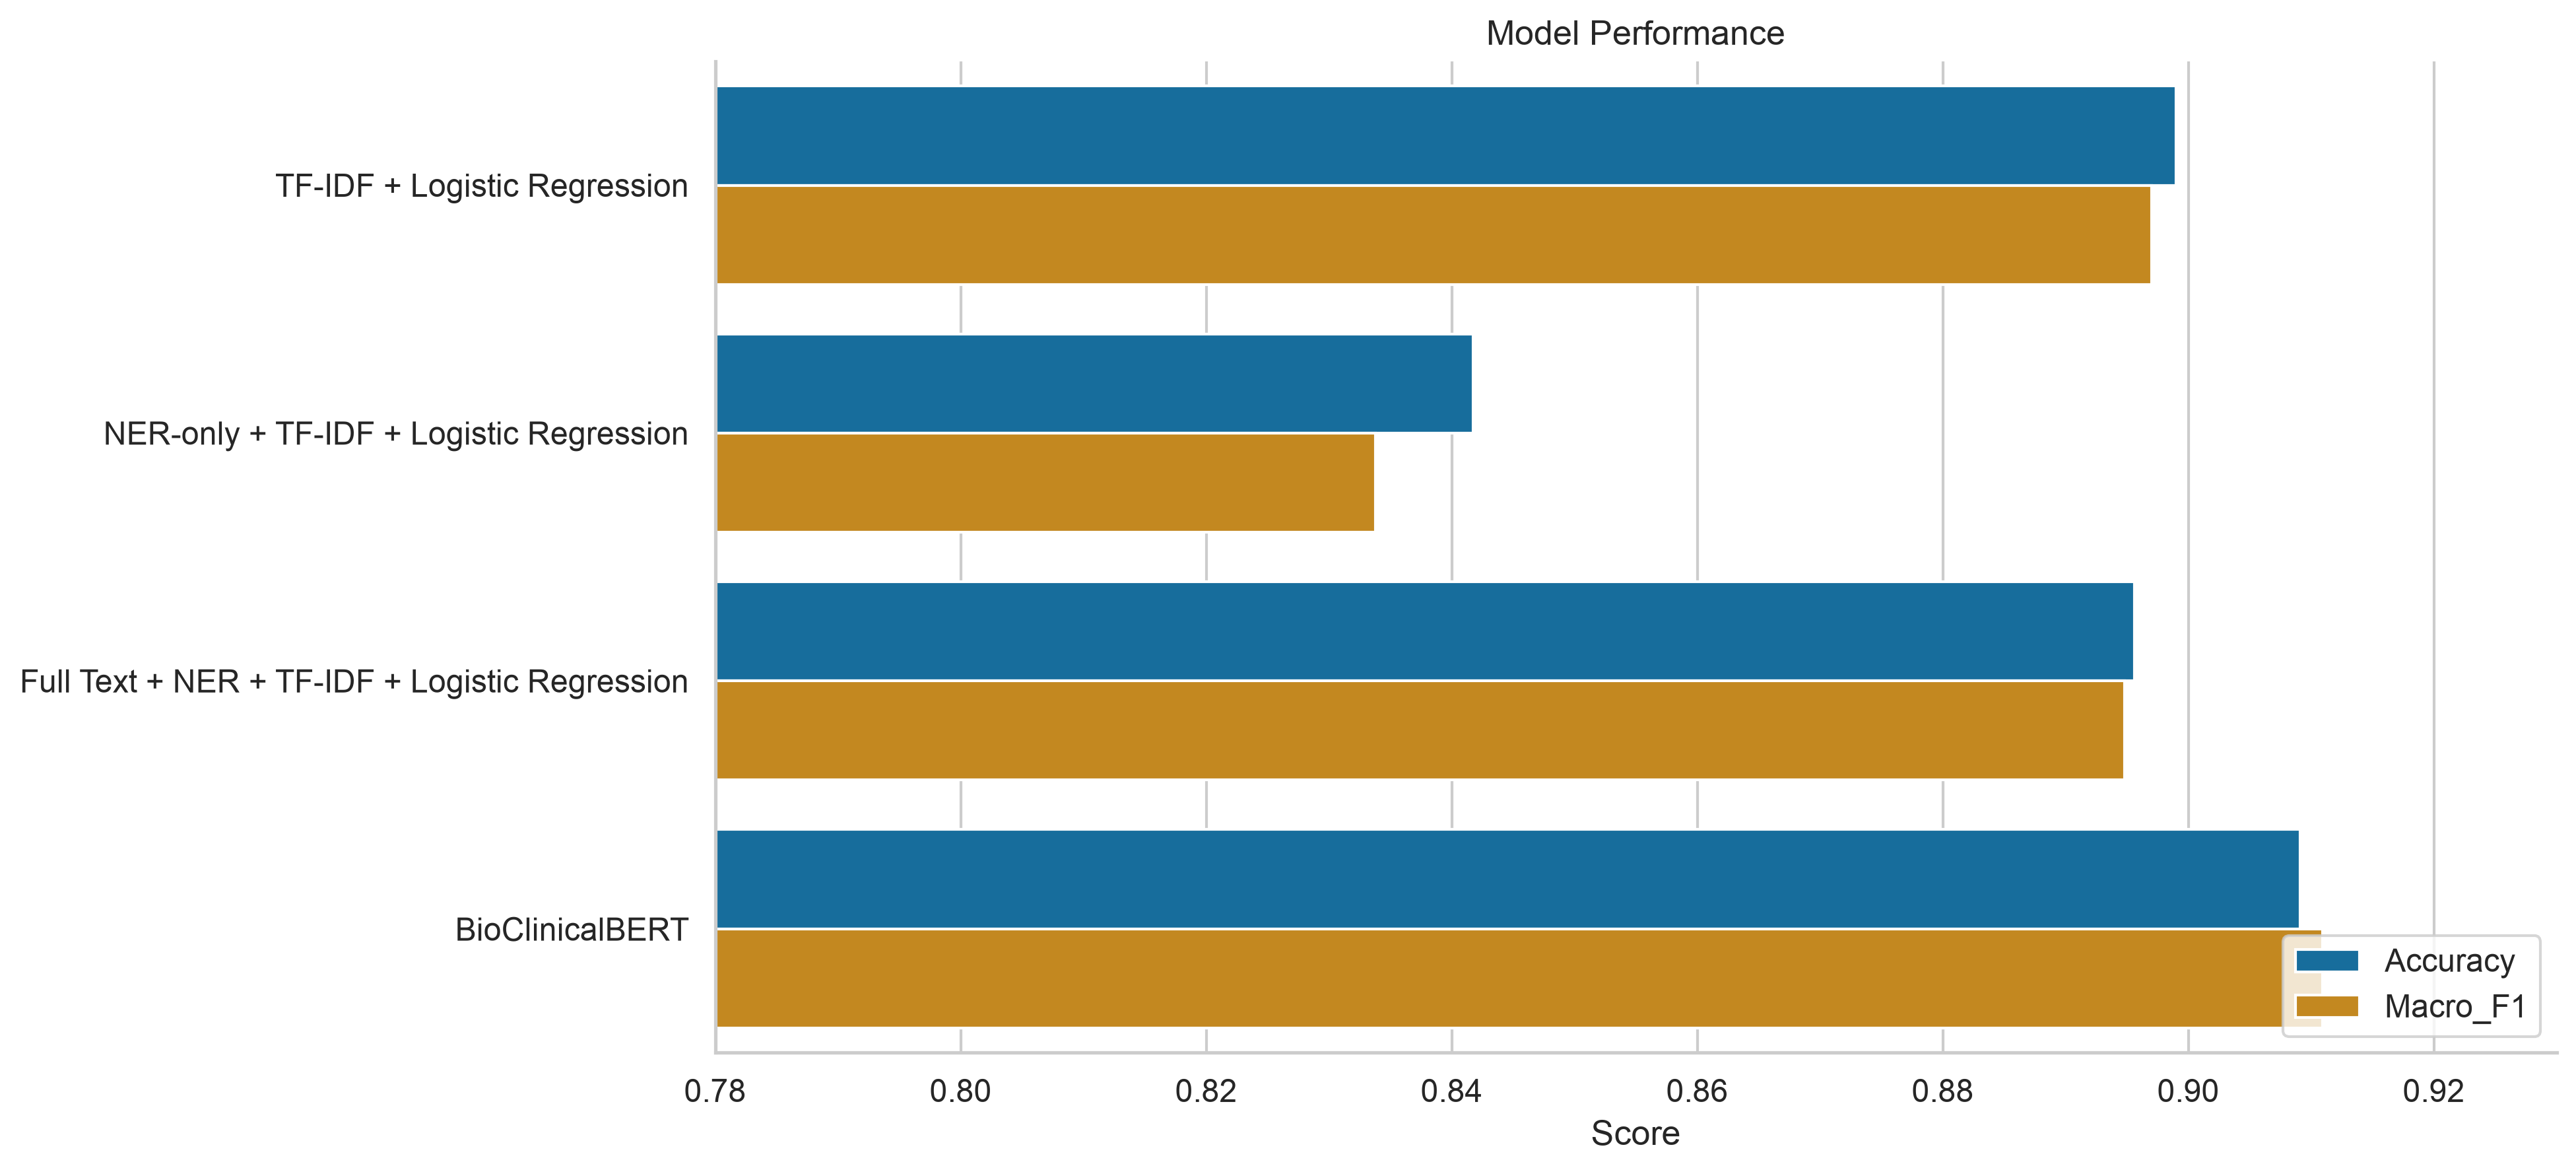

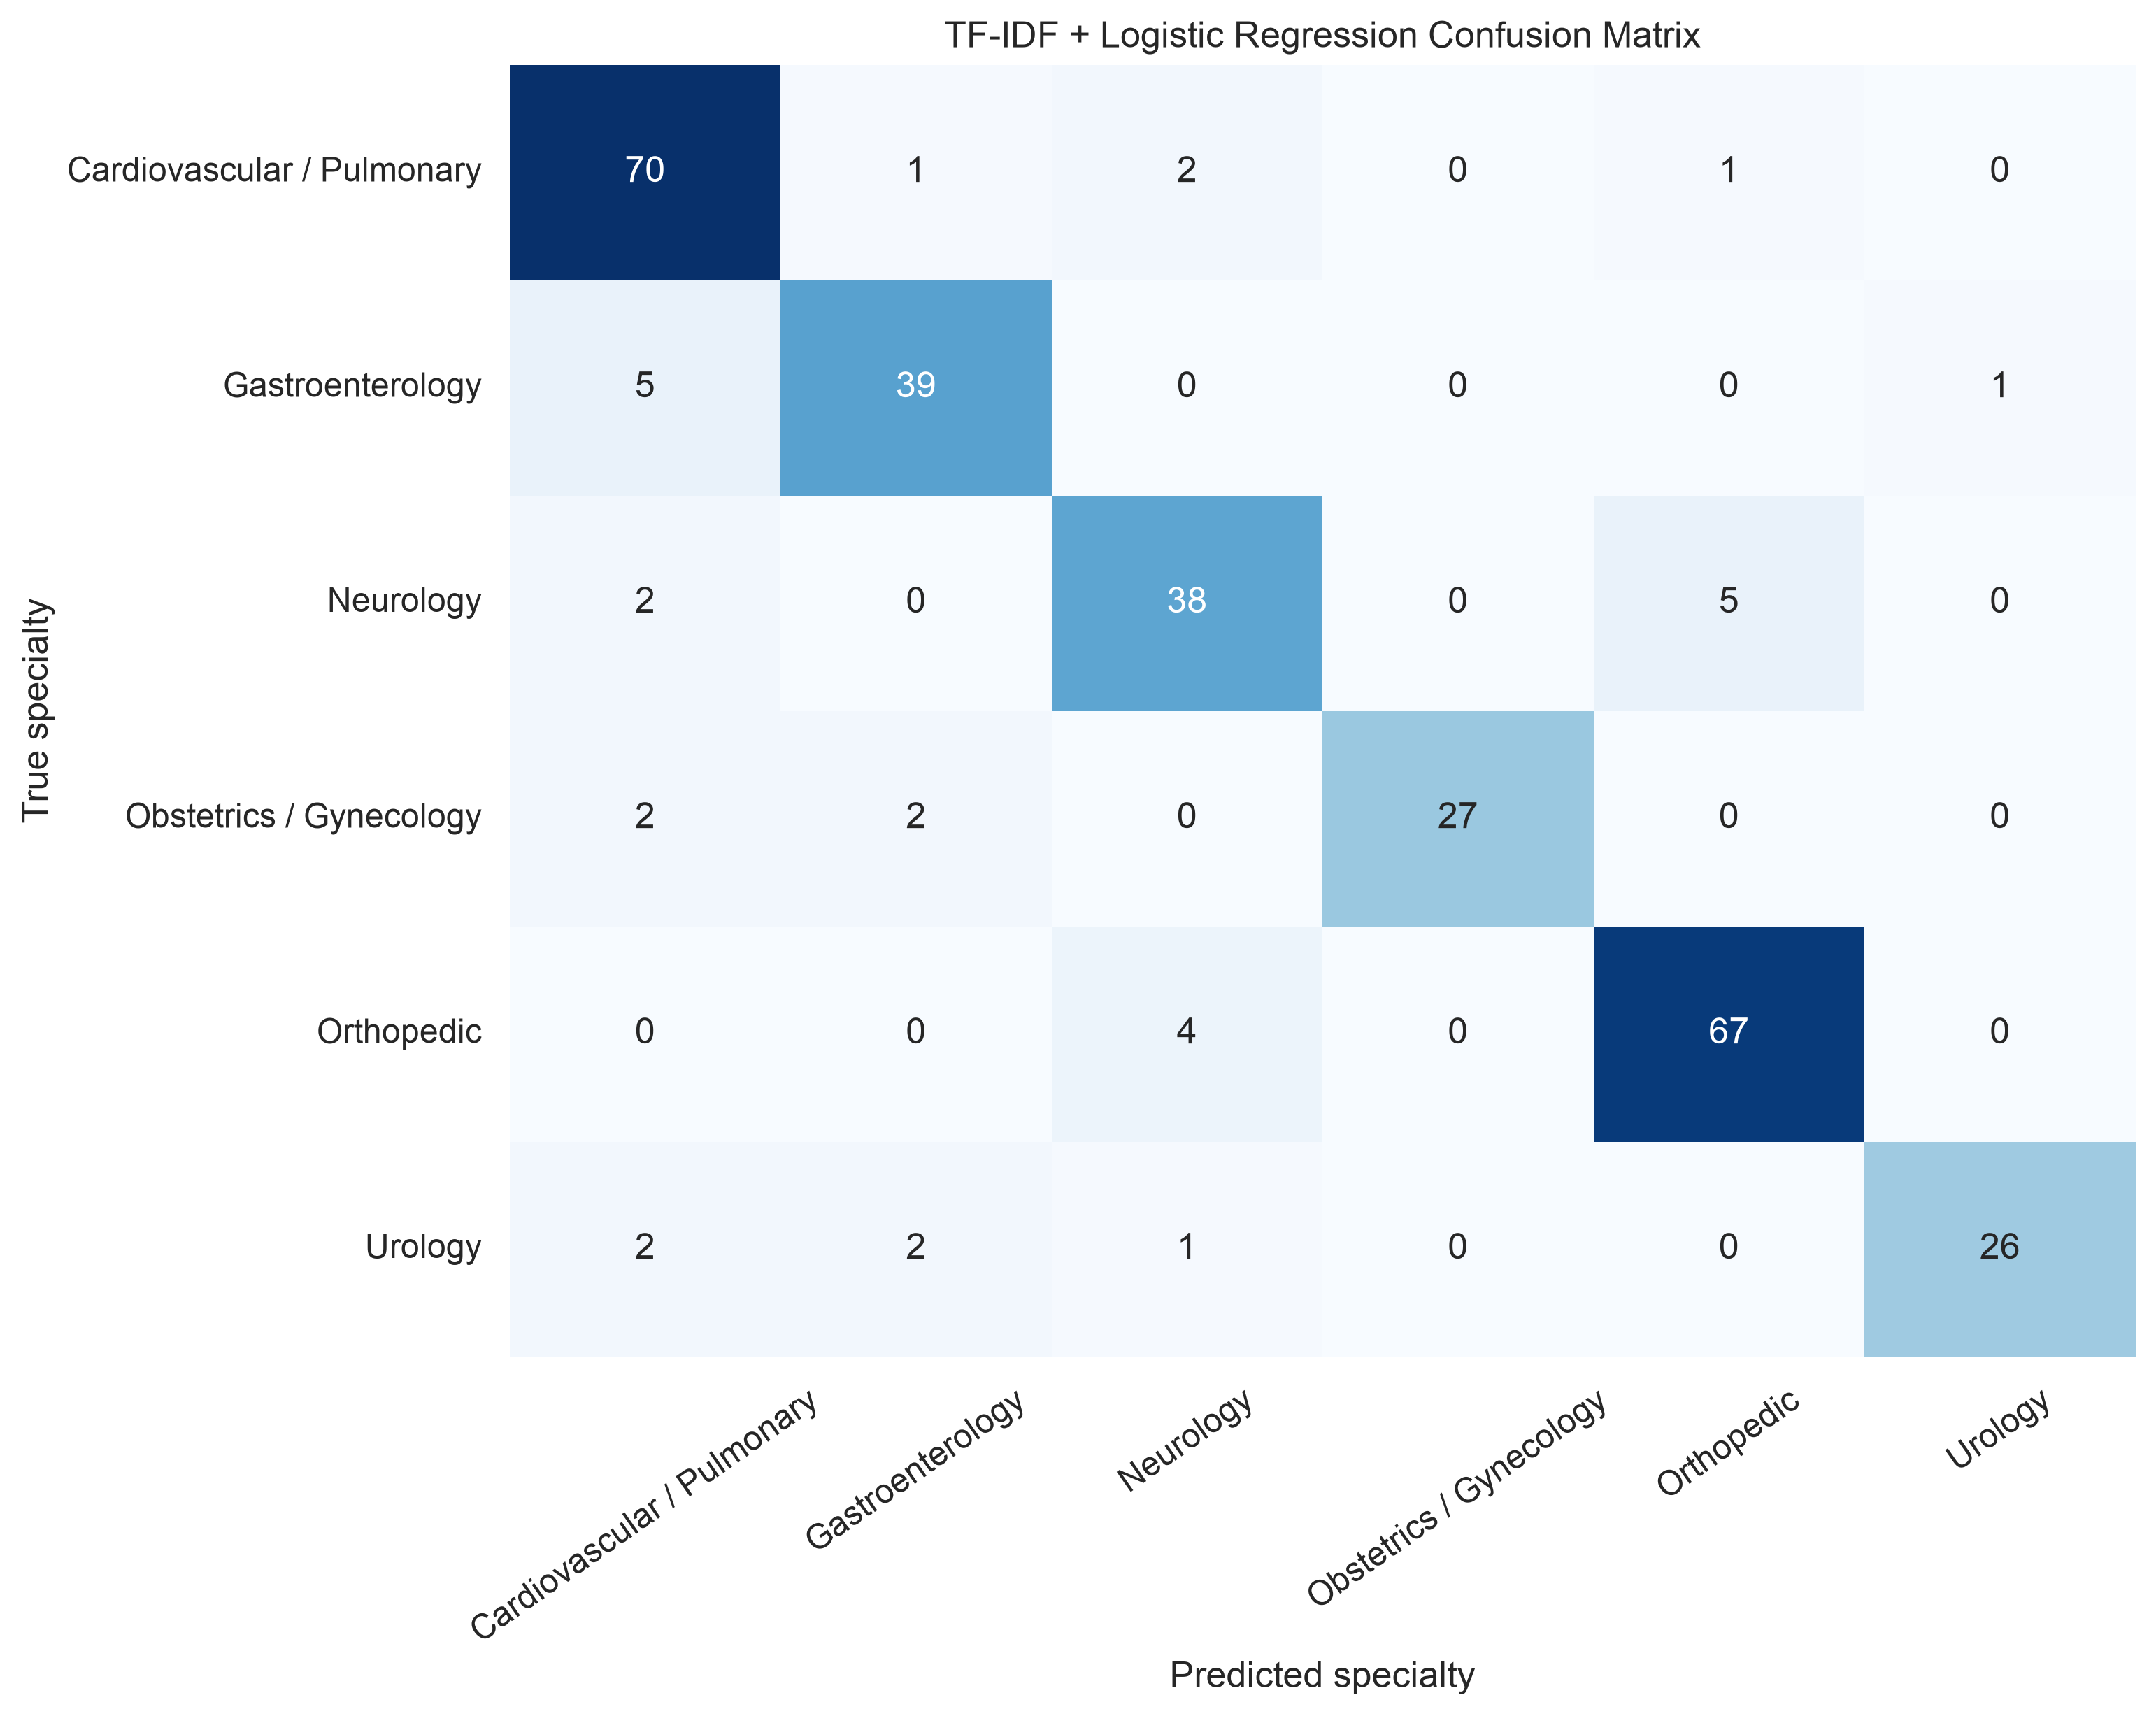

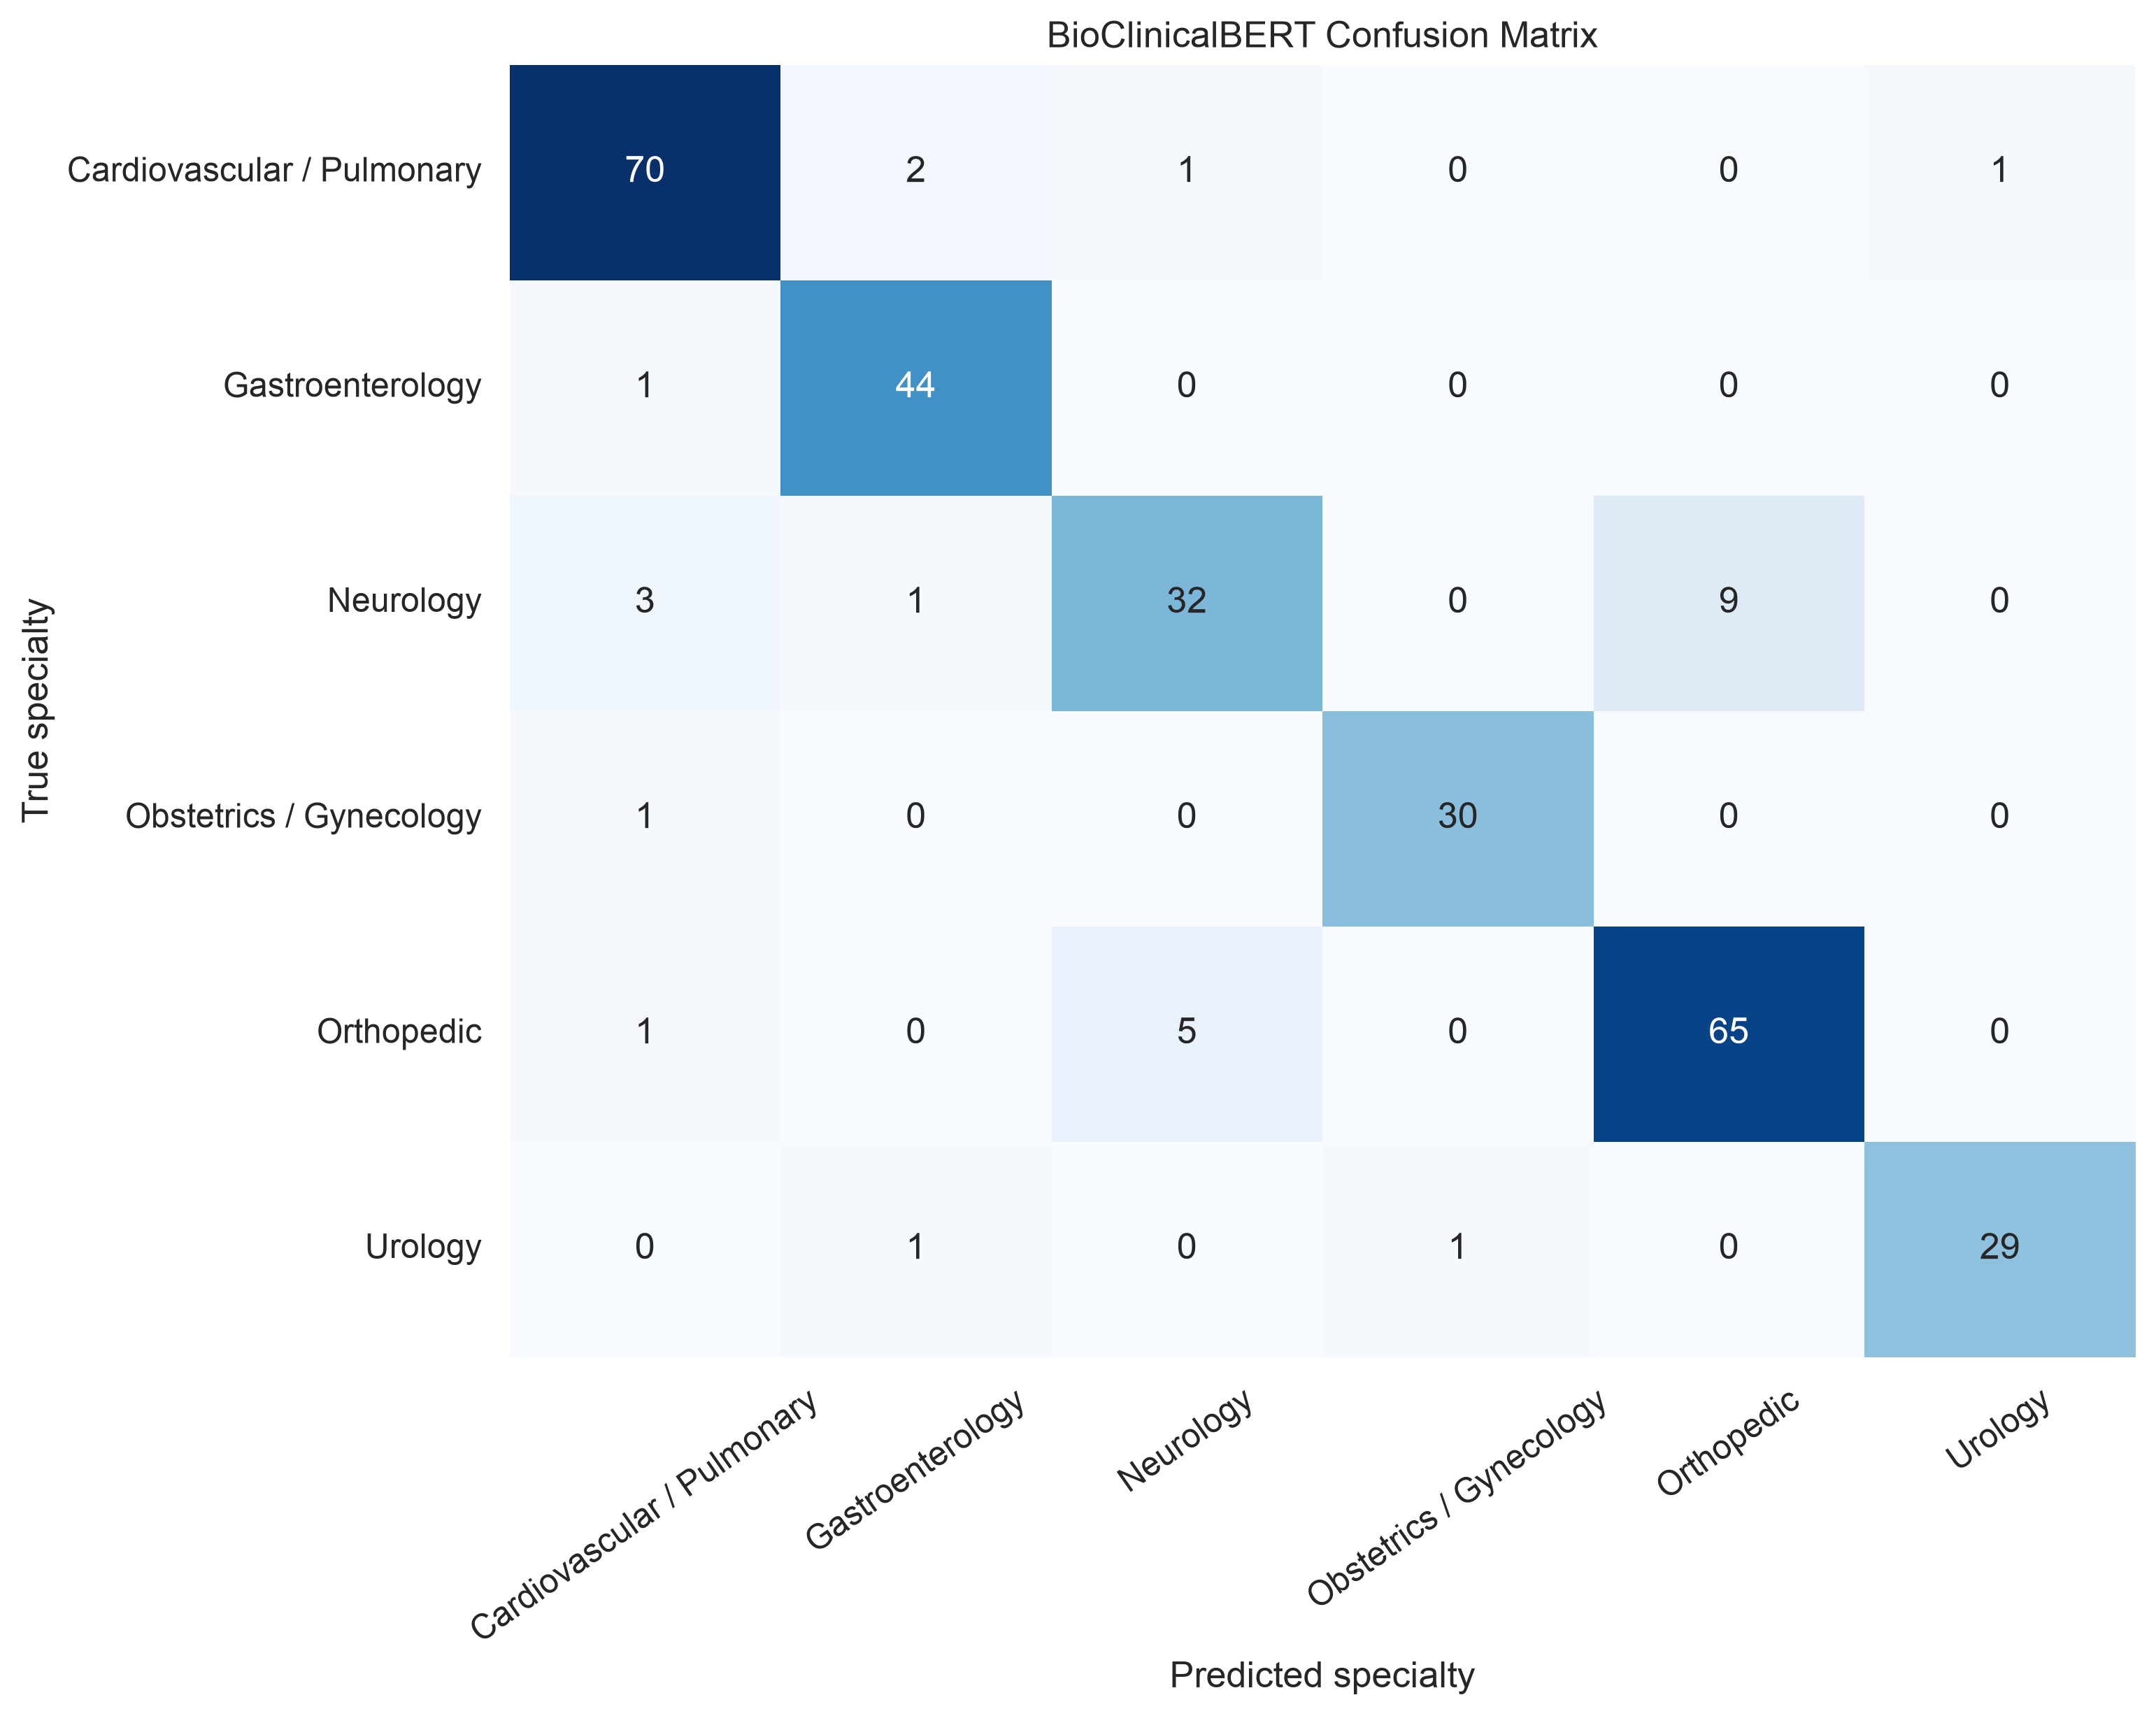

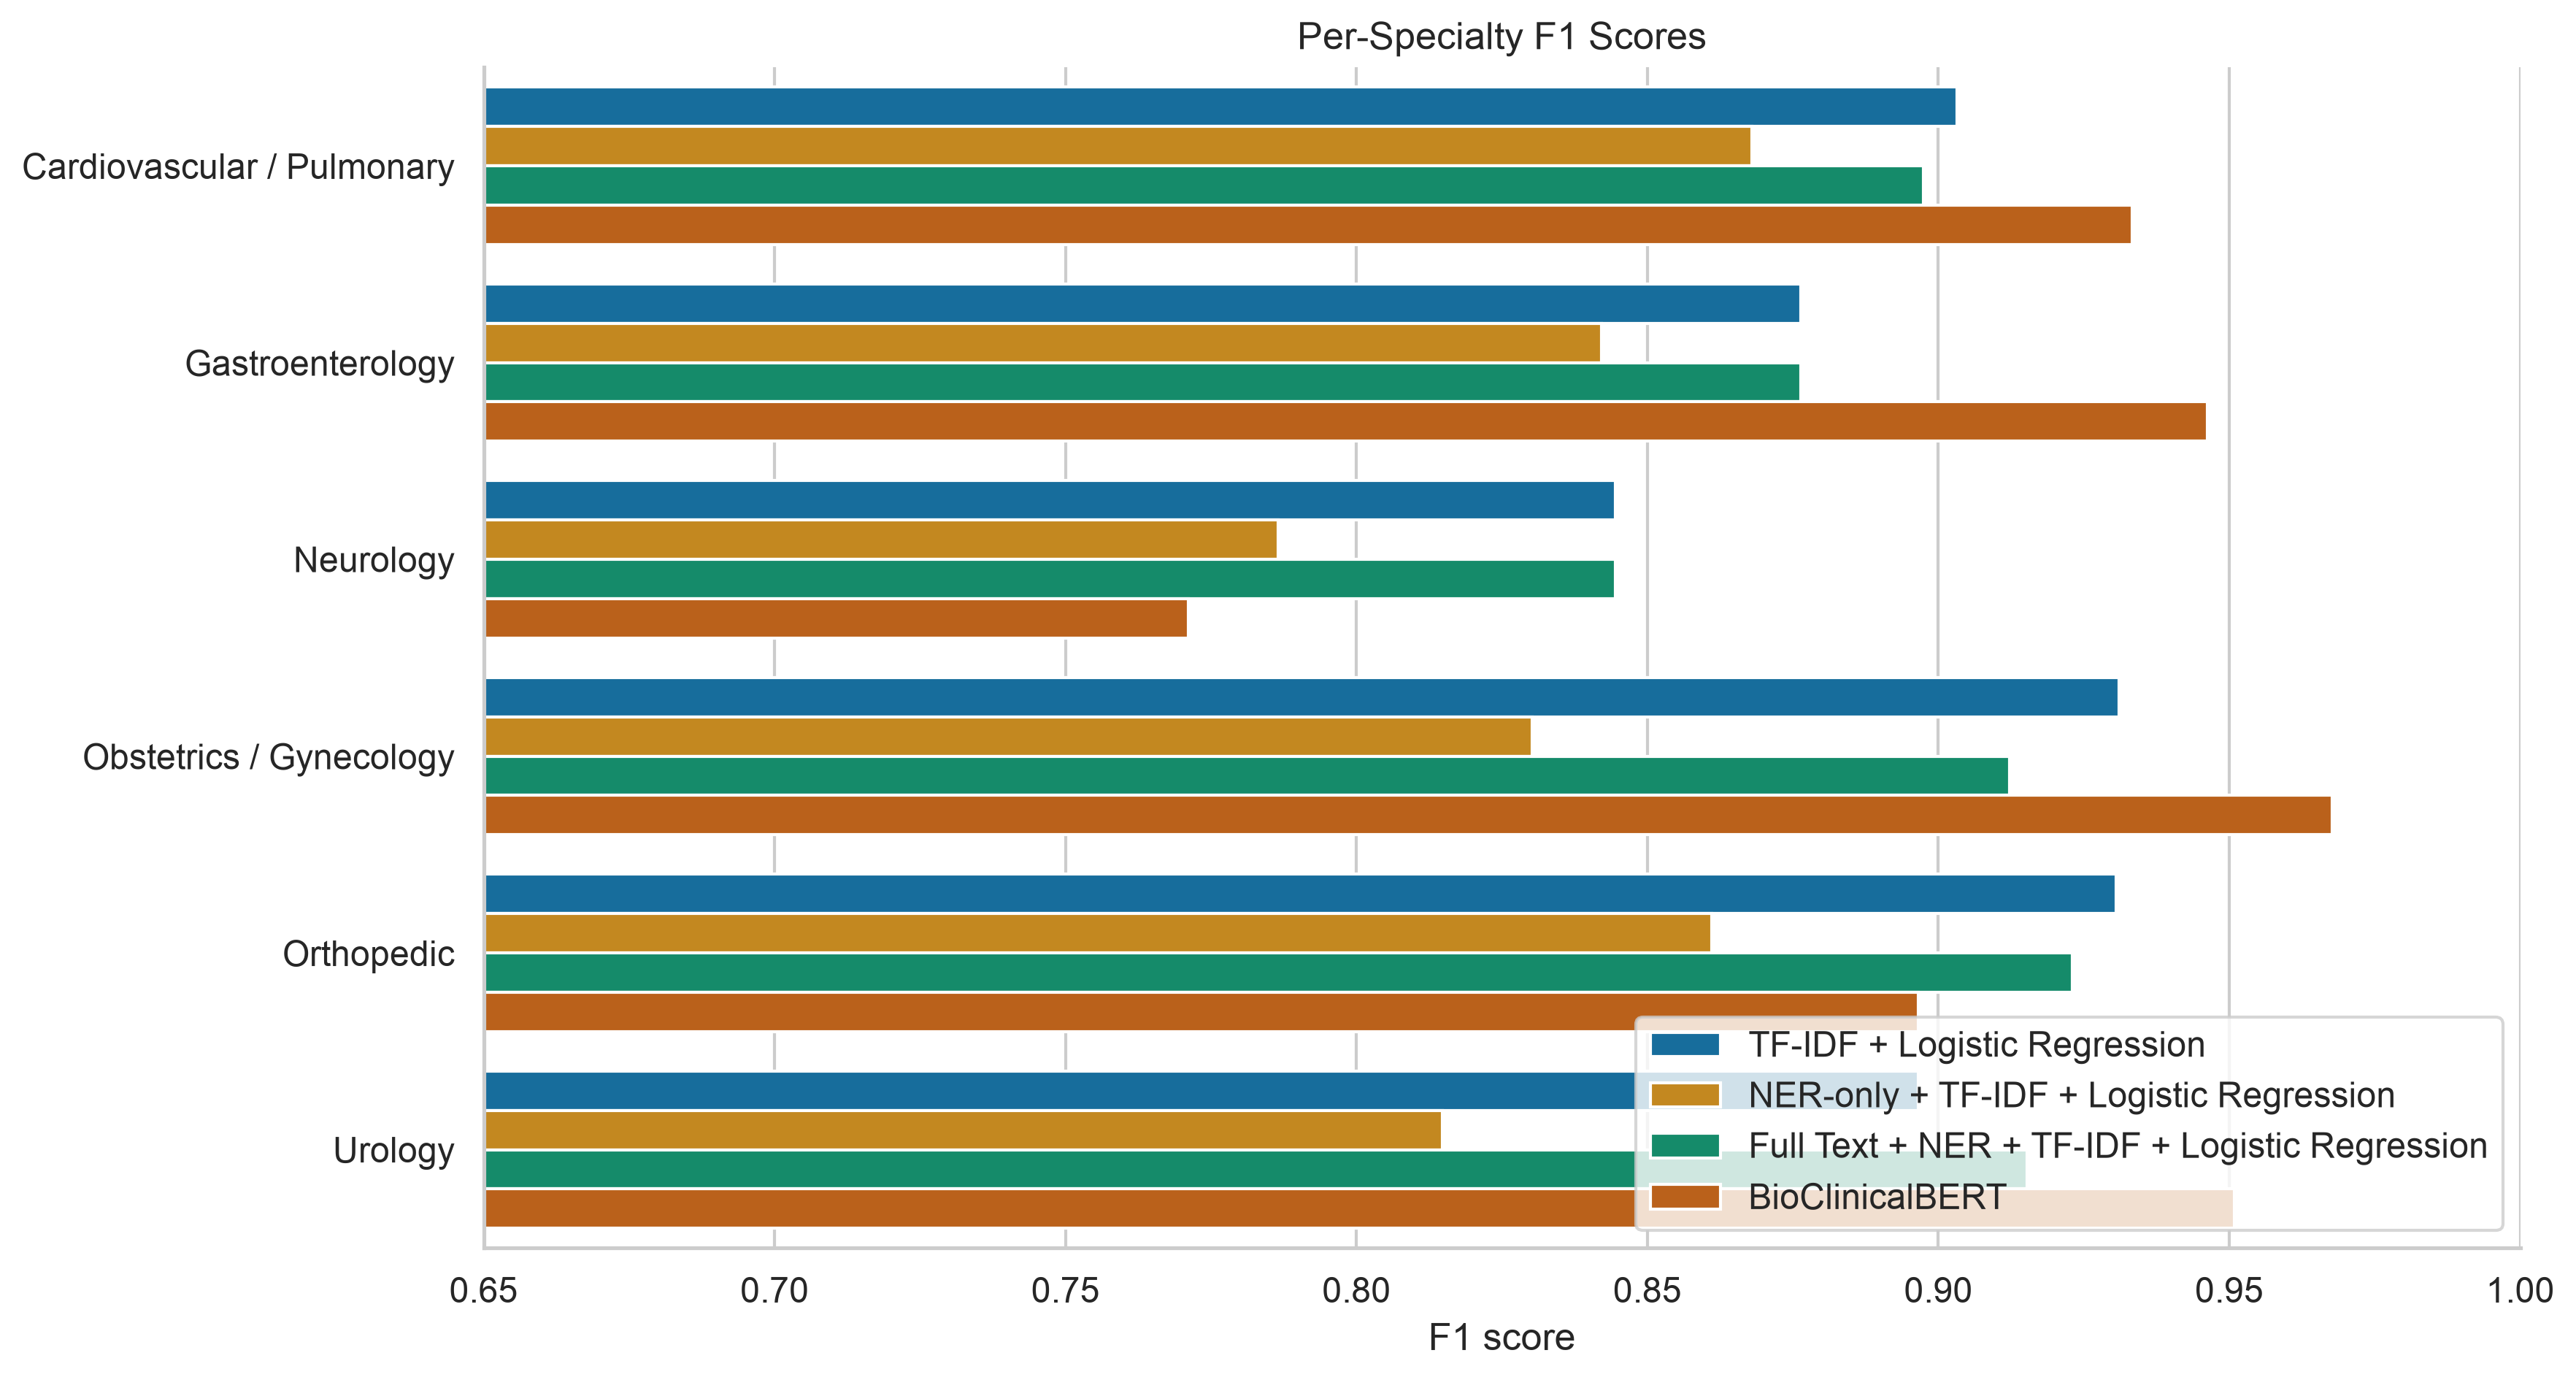

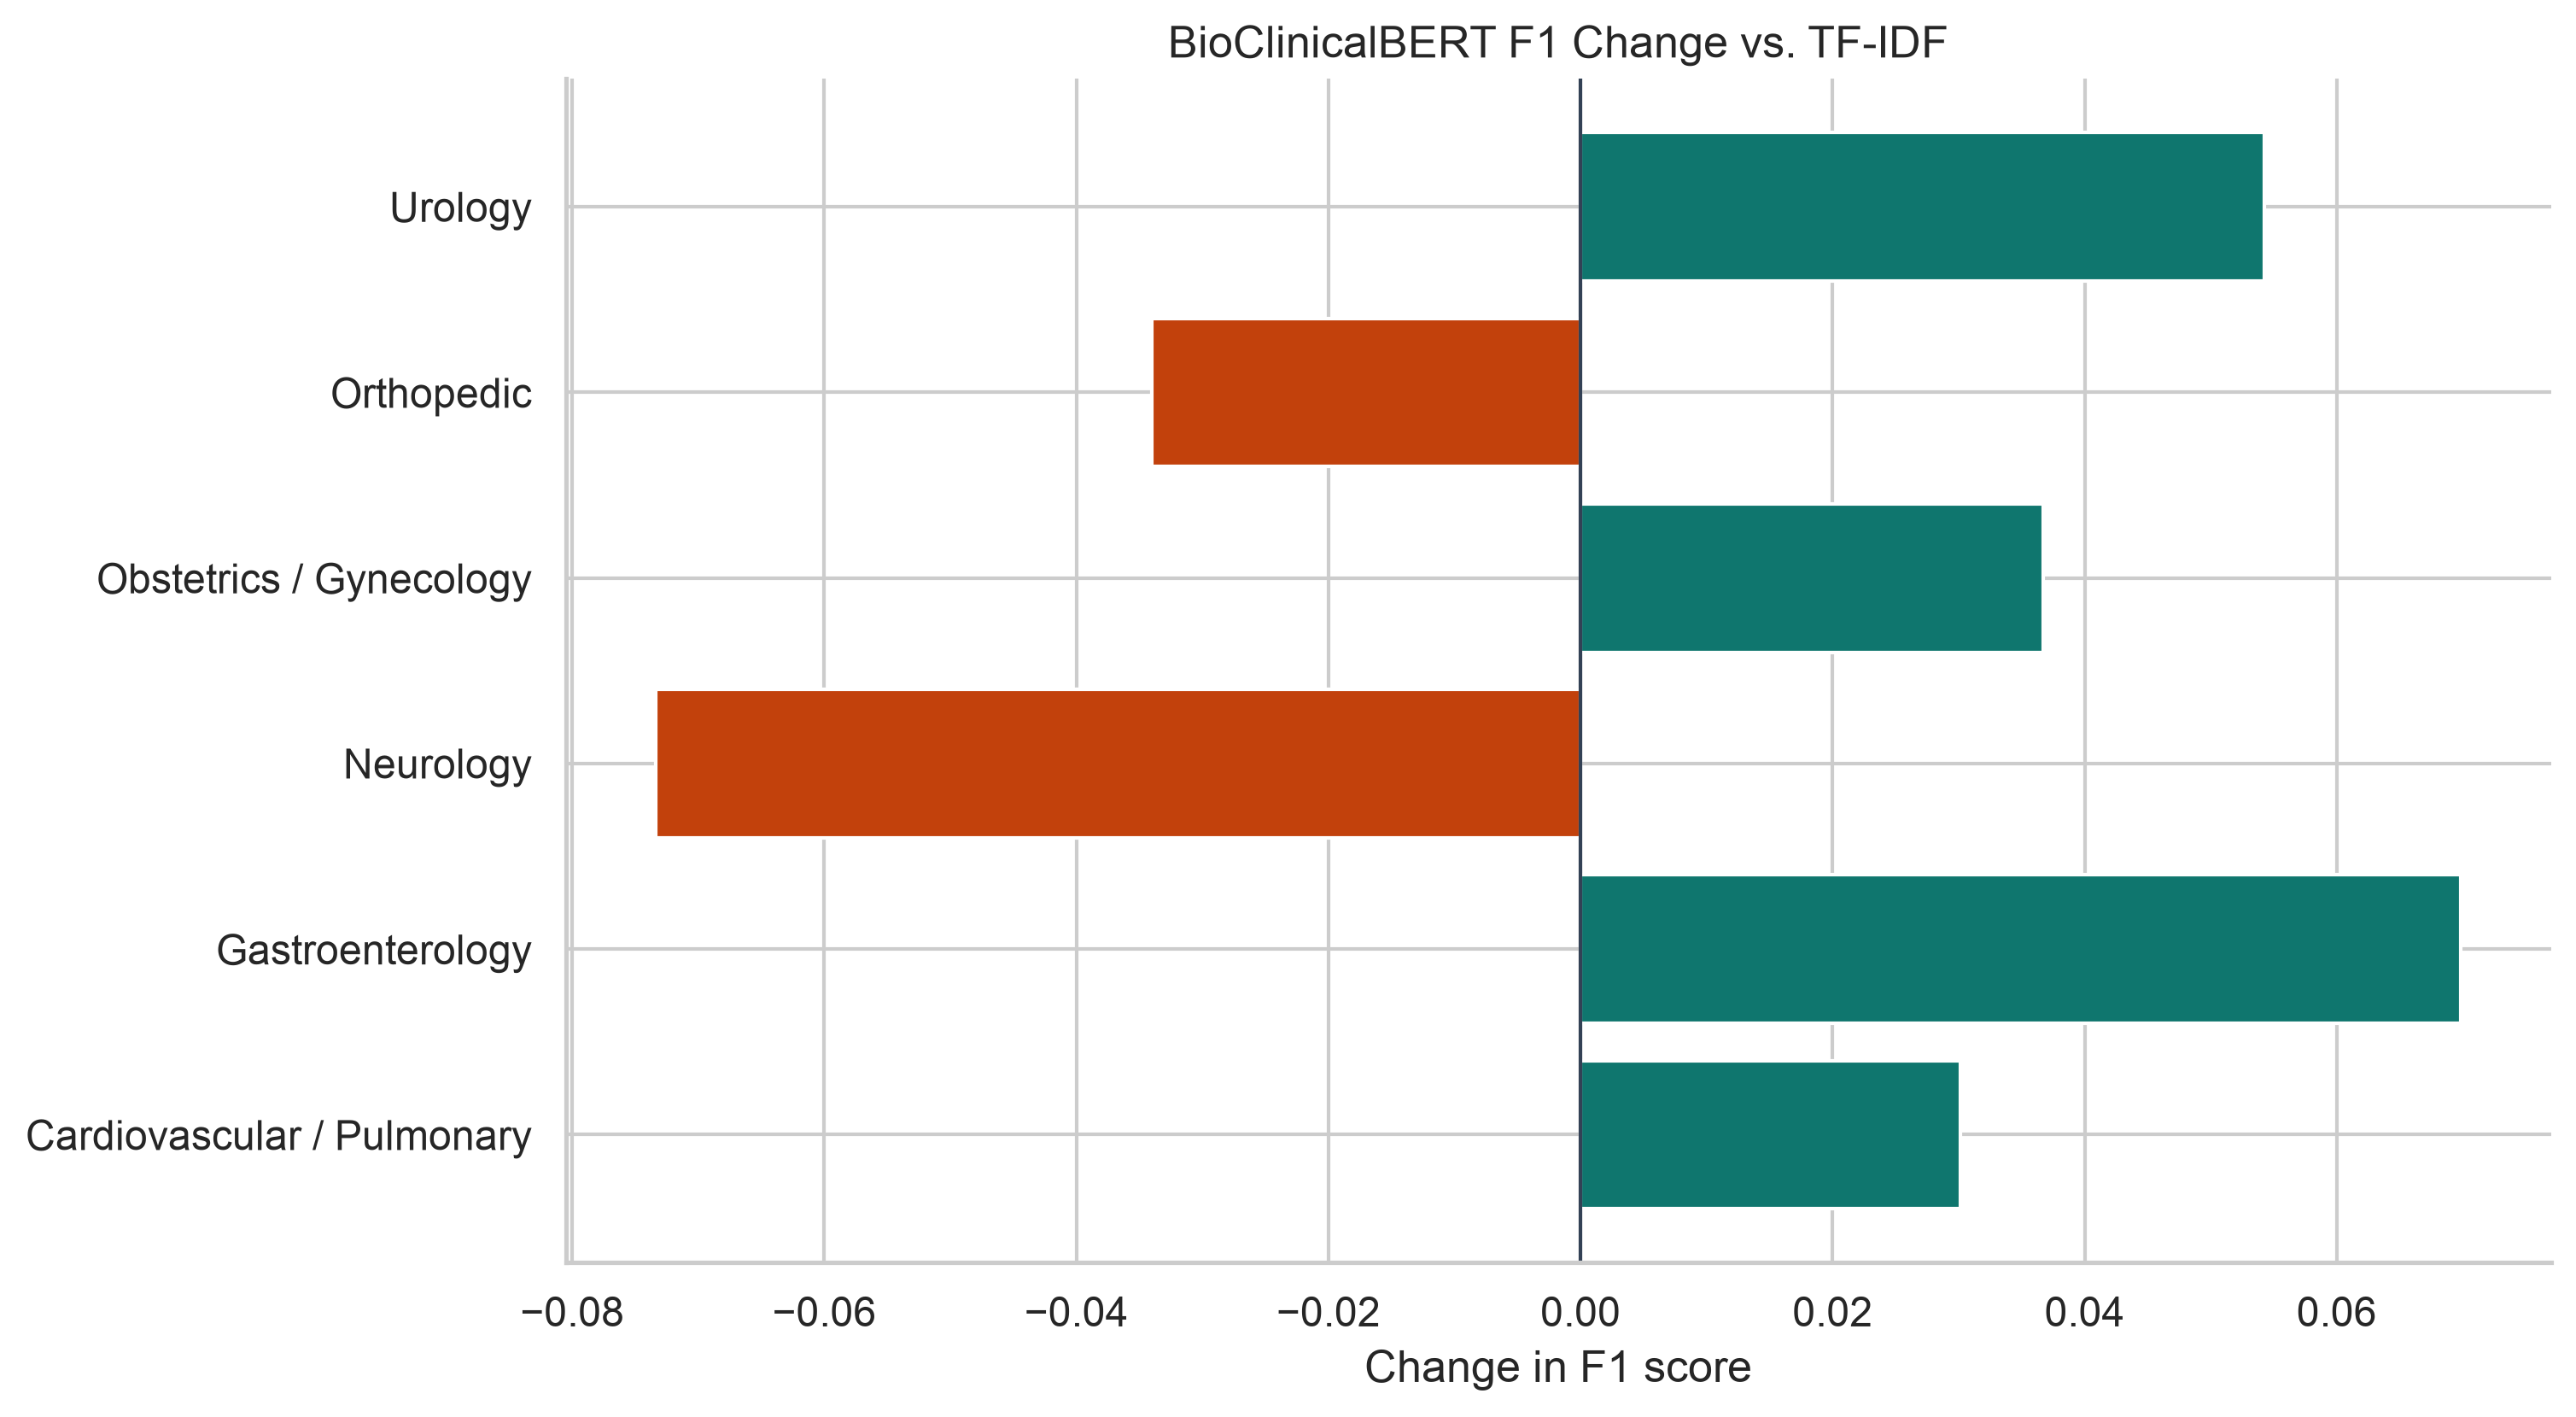

In [20]:
for filename in [
    "model_comparison.png",
    "confusion_matrix_tfidf.png",
    "confusion_matrix_bert.png",
    "per_class_f1.png",
    "bert_vs_tfidf_f1.png",
]:
    display(Image(filename=PROJECT_ROOT / "figures" / filename, width=900))

## 6. Neurology truncation analysis

Neurology test notes average **691.93** untruncated BioClinicalBERT tokens, the median is **678**, and **39/45 (86.7%)** exceed the 256-token limit. BioClinicalBERT Neurology precision is 0.84 while recall is 0.71.

Truncation is therefore a **plausible contributor** to reduced Neurology recall, not proven causation. A controlled follow-up should test longer context, section-aware sampling, and chunk-level aggregation while keeping the split and training budget fixed.

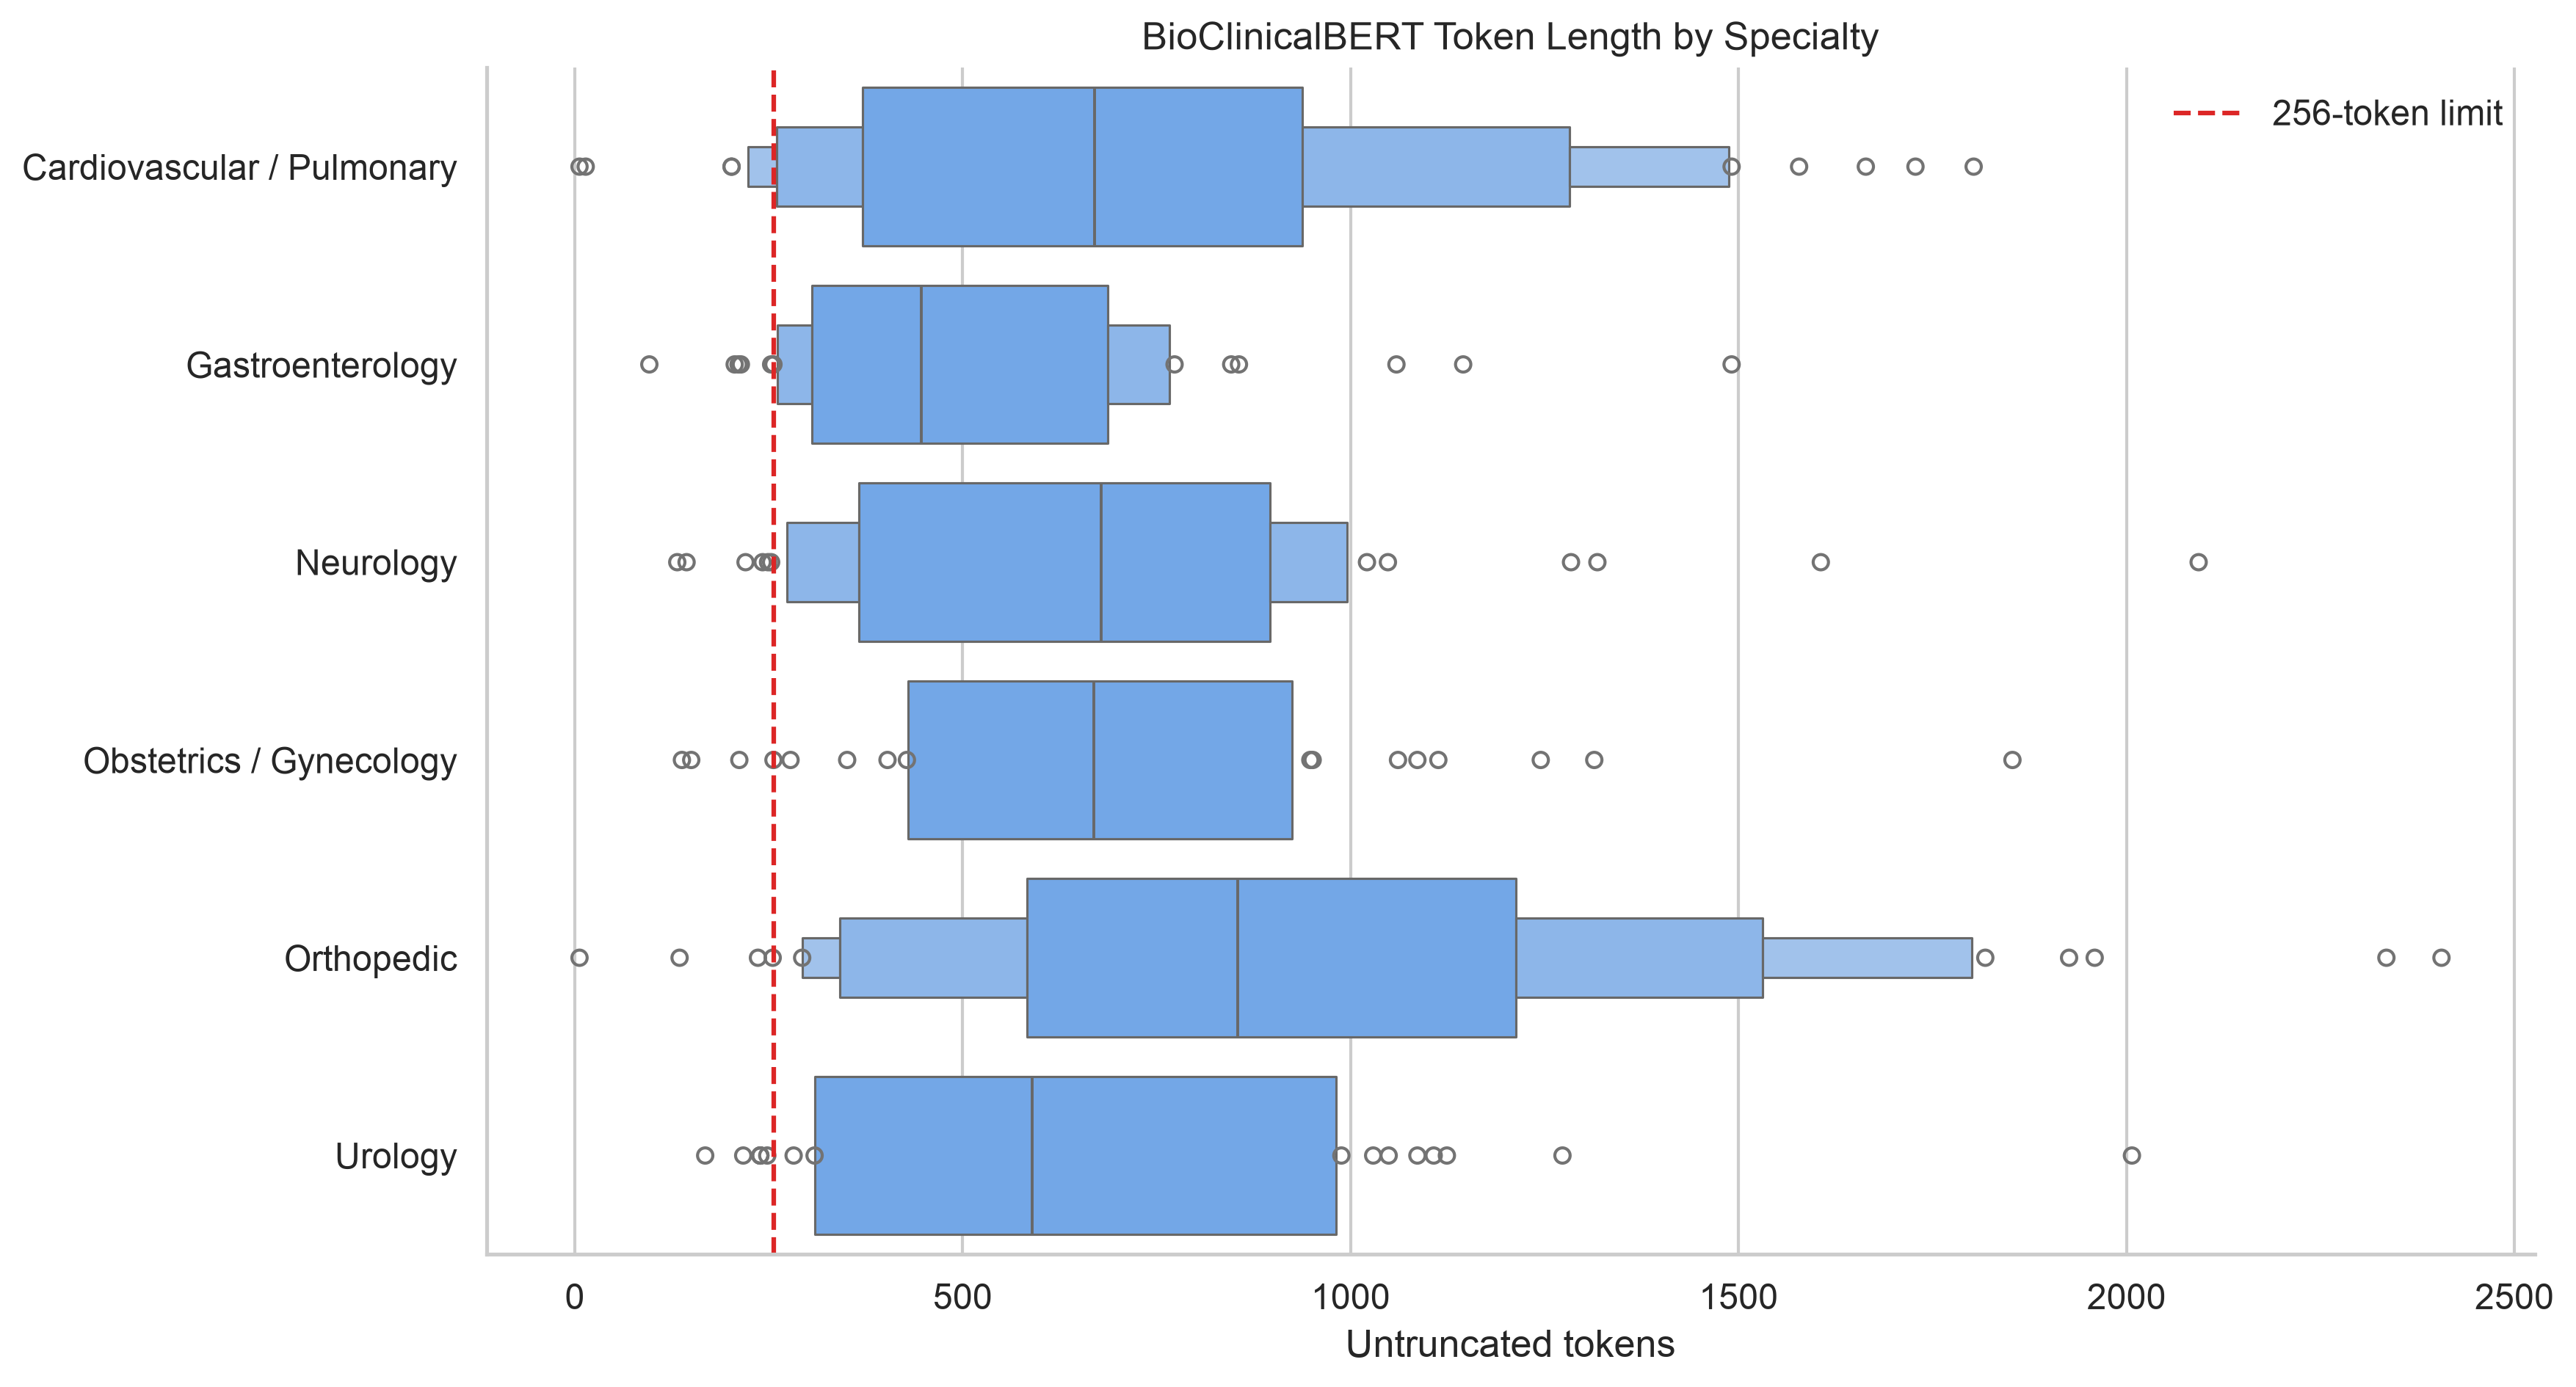

In [21]:
display(Image(
    filename=PROJECT_ROOT / "figures" / "token_length_by_specialty.png",
    width=950,
))

## 7. Reproduce from the command line

```bash
python -m src.data --input data/mtsamples.csv --output-dir data
python -m src.ner --input data/mtsamples.csv --output data/mtsamples_with_ner.csv
python -m src.baseline --data data/mtsamples_with_ner.csv
python -m src.train_bert --data data/mtsamples.csv --device auto
```

Or run the orchestrator:

```bash
python scripts/run_pipeline.py --raw-data data/mtsamples.csv --device auto
```